# **Exploratory Data Analysis (EDA)**

## Project Overview

Exploratory Data Analysis (EDA) is the process of examining and visualizing a dataset to understand its structure, identify patterns, detect outliers, and discover relationships between variables.

## Objectives

* Load and inspect a dataset.
* Calculate descriptive statistics.
* Identify missing values and duplicate records.
* Create visualizations using Matplotlib and Seaborn.
* Analyze relationships and correlations between variables.
* Summarize key findings from the data.

## Tools and Technologies

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Google Colab


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv('advertising.csv')

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!

First 5 rows:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (200, 4)

Column Names:
['TV', 'Radio', 'Newspaper', 'Sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate Rows: 0


In [4]:
print("Descriptive Statistics:")
display(df.describe())

Descriptive Statistics:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## 4. Sales Distribution

A histogram helps us understand the distribution of sales values by showing how frequently different sales ranges occur.

In this step, we visualize the `Sales` column to identify common sales ranges and understand the overall distribution of sales.


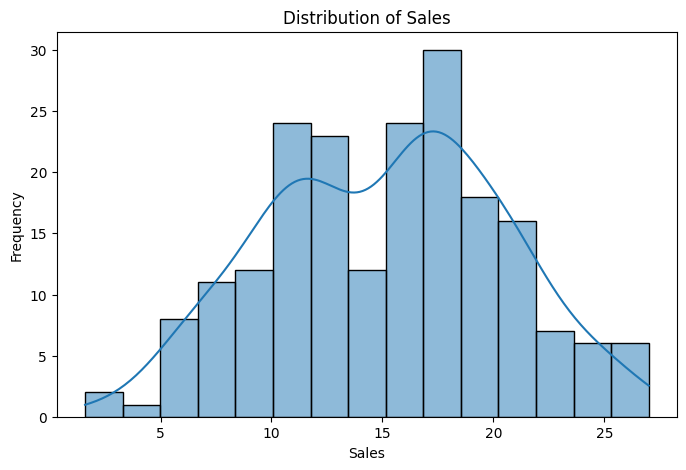

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Sales'], bins=15, kde=True)

plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

## 5. Advertising Spending Distribution

Histograms help us understand how values are distributed across different ranges.

In this step, we create histograms for TV, Radio, and Newspaper advertising spending to compare their distributions and identify common spending ranges.


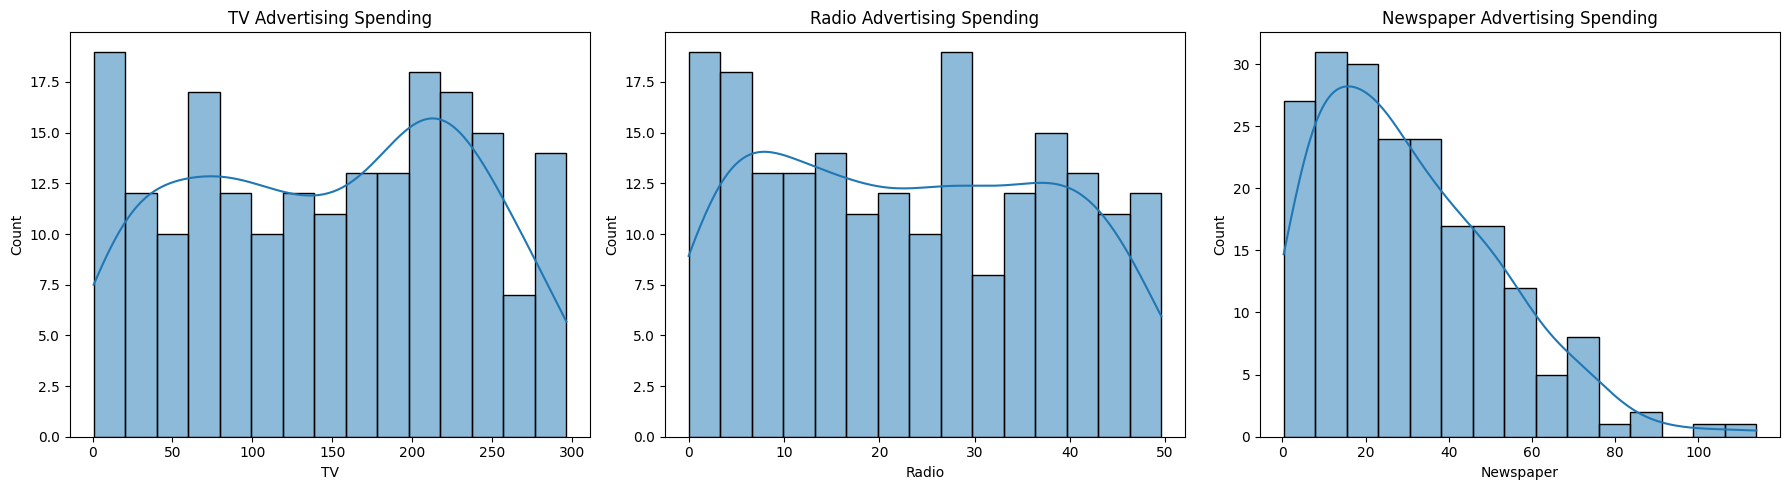

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['TV'], bins=15, kde=True, ax=axes[0])
axes[0].set_title('TV Advertising Spending')
axes[0].set_xlabel('TV')

sns.histplot(df['Radio'], bins=15, kde=True, ax=axes[1])
axes[1].set_title('Radio Advertising Spending')
axes[1].set_xlabel('Radio')

sns.histplot(df['Newspaper'], bins=15, kde=True, ax=axes[2])
axes[2].set_title('Newspaper Advertising Spending')
axes[2].set_xlabel('Newspaper')

plt.tight_layout()
plt.show()

## 6. Relationship Between Advertising and Sales

Scatter plots help us understand the relationship between two numerical variables.

In this step, we compare TV, Radio, and Newspaper advertising spending with Sales to identify possible trends and determine which advertising channels appear more strongly associated with sales.


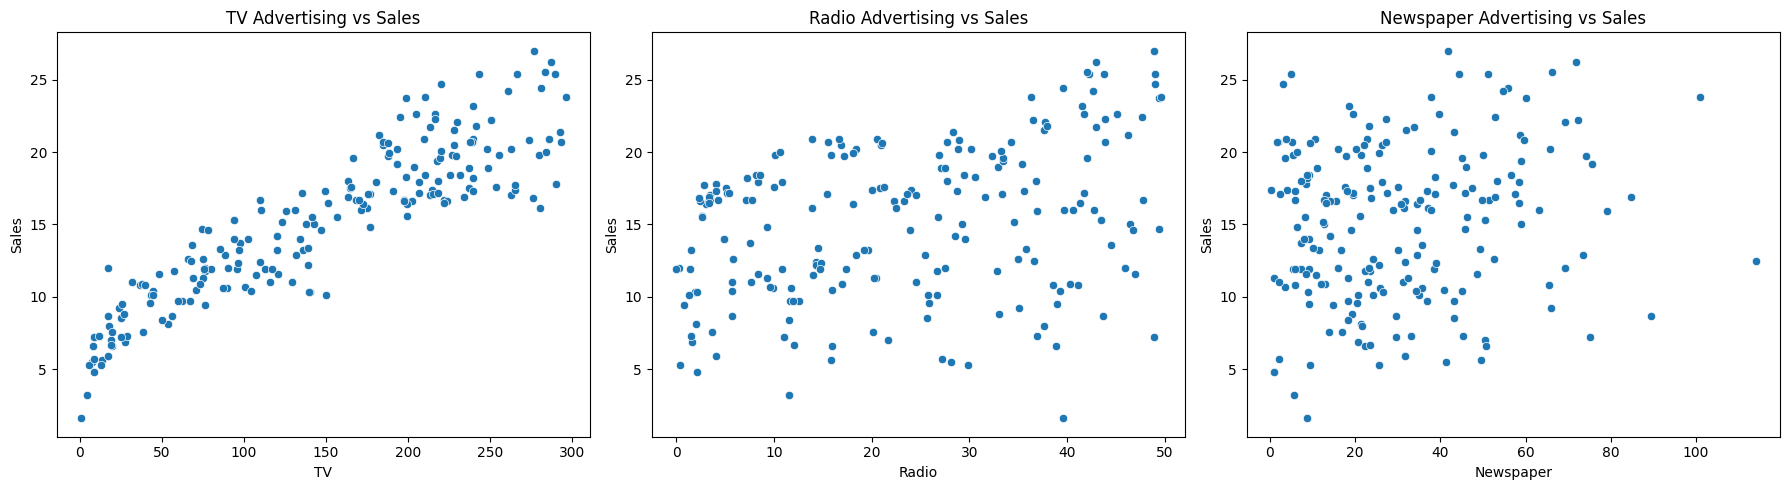

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='TV', y='Sales', ax=axes[0])
axes[0].set_title('TV Advertising vs Sales')

sns.scatterplot(data=df, x='Radio', y='Sales', ax=axes[1])
axes[1].set_title('Radio Advertising vs Sales')

sns.scatterplot(data=df, x='Newspaper', y='Sales', ax=axes[2])
axes[2].set_title('Newspaper Advertising vs Sales')

plt.tight_layout()
plt.show()

## 7. Correlation Analysis

Correlation analysis helps us understand the strength and direction of relationships between numerical variables.

A correlation value ranges from -1 to +1:

* **+1:** Perfect positive relationship.
* **0:** No linear relationship.
* **-1:** Perfect negative relationship.

In this step, we create a heatmap to examine the correlations between TV, Radio, Newspaper, and Sales.


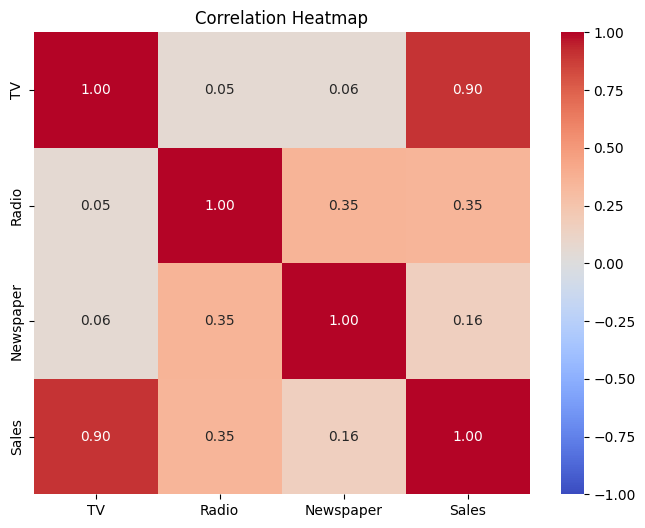

In [8]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.show()

## 8. Outlier Detection Using Boxplots

Boxplots help identify potential outliers by displaying the median, quartiles, and values that fall unusually far from the rest of the data.

In this step, we create boxplots for TV, Radio, Newspaper, and Sales to examine the distributions and identify potential outliers.

An observation flagged by a boxplot is not necessarily an error; it may be a valid data point.


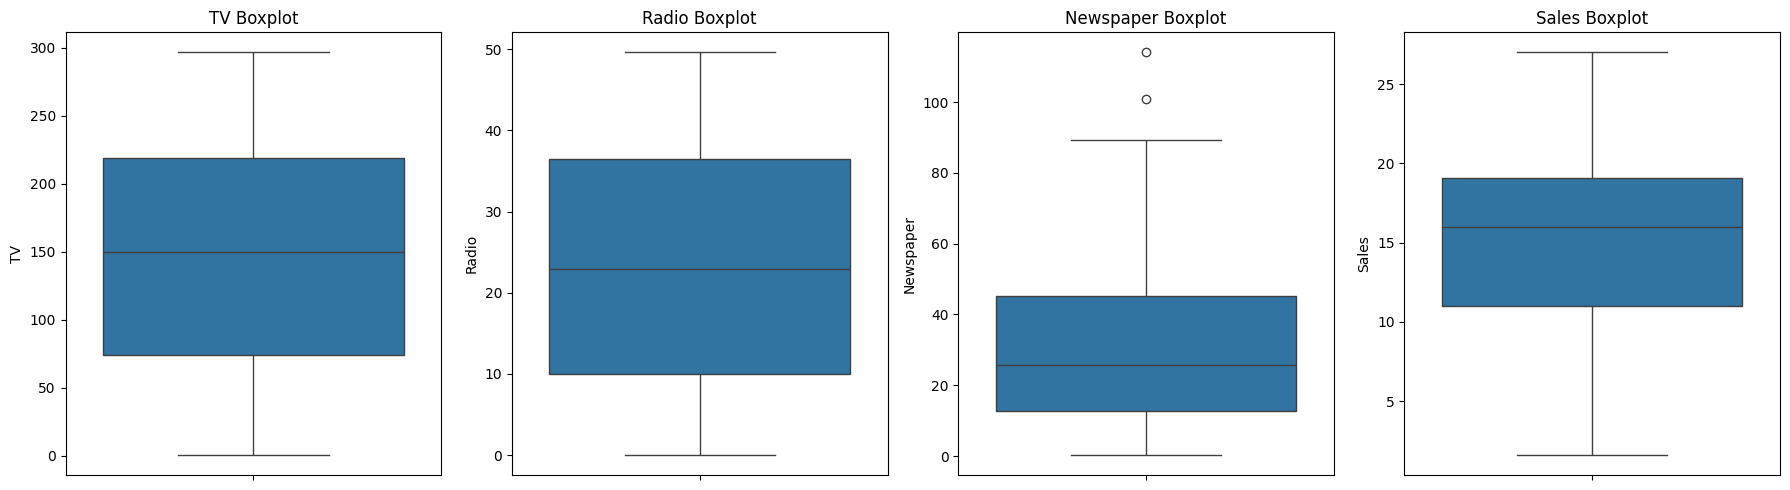

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

columns = ['TV', 'Radio', 'Newspaper', 'Sales']

for ax, column in zip(axes, columns):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title(f'{column} Boxplot')

plt.tight_layout()
plt.show()

## 9. Key Findings and Insights

In this step, we summarize the relationships between advertising spending and sales using correlation values.

We identify which advertising channel has the strongest positive correlation with sales. These findings help us understand patterns in the dataset, although correlation alone does not establish causation.


In [10]:
sales_correlation = df.corr(numeric_only=True)['Sales'].drop('Sales')
sales_correlation = sales_correlation.sort_values(ascending=False)

print("Correlation of Advertising Channels with Sales:")
display(sales_correlation.to_frame(name='Correlation with Sales'))

print("\nStrongest Correlation with Sales:")
print(sales_correlation.idxmax())

Correlation of Advertising Channels with Sales:


,Correlation with Sales
TV,0.901208
Radio,0.349631
Newspaper,0.157960



Strongest Correlation with Sales:
TV


## 10. Conclusion

In this project, we performed Exploratory Data Analysis (EDA) on the Advertising dataset using Python.

The following tasks were completed:

* Loaded and inspected the dataset.
* Calculated descriptive statistics.
* Checked for missing values and duplicate records.
* Visualized sales and advertising spending distributions using histograms.
* Examined relationships between advertising spending and sales using scatter plots.
* Created a correlation heatmap to understand relationships between numerical variables.
* Used boxplots to identify potential outliers.
* Analyzed correlations to identify the advertising channel most strongly associated with sales.

### Key Findings

* TV advertising has the strongest positive correlation with sales.
* Radio advertising shows a weaker positive correlation with sales than TV advertising.
* Newspaper advertising has a relatively weak relationship with sales.
* Histograms and boxplots help us understand the distributions and identify potential outliers.

Overall, EDA helps us understand a dataset, discover patterns, and prepare for further analysis and predictive modeling.
